# Credit Card Fraud Detection: Random Forest vs XGBoost vs Logistic Regression

**Goal:** detect fraudulent transactions in a highly imbalanced dataset (~0.17% fraud).

**What this notebook covers**
1. EDA and class imbalance
2. Leakage-safe train / validation / test split
3. Baseline (Logistic Regression) vs Random Forest vs XGBoost
4. Imbalance handling: class weights vs SMOTE
5. Metrics that matter for fraud: PR-AUC, recall at fixed precision (not accuracy)
6. Cost-based threshold tuning (chosen on validation, reported on test)
7. Explainability with SHAP

**Data:** Kaggle "Credit Card Fraud Detection" (ULB). Download `creditcard.csv` and place it next to this notebook.
https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

In [13]:
import os, urllib.request
import pandas as pd

URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
DATA_PATH = "creditcard.csv"

# remove a partial/old file so we don't reuse the truncated one
if os.path.exists(DATA_PATH) and len(pd.read_csv(DATA_PATH)) < 280000:
    os.remove(DATA_PATH)

if not os.path.exists(DATA_PATH):
    print("Downloading (~144 MB), please wait...")
    urllib.request.urlretrieve(URL, DATA_PATH)

check = pd.read_csv(DATA_PATH)
print("Rows:", len(check), "| Frauds:", int(check["Class"].sum()))
assert len(check) == 284807, "File incomplete, run this cell again"
del check

Rows: 284807 | Frauds: 492


In [14]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import shap

RANDOM_STATE = 42
DATA_PATH = "creditcard.csv"   # change if your file is elsewhere

## 1. Load data and check class imbalance

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081
Shape after dropping incomplete rows: (284807, 31)

Class counts:
 Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


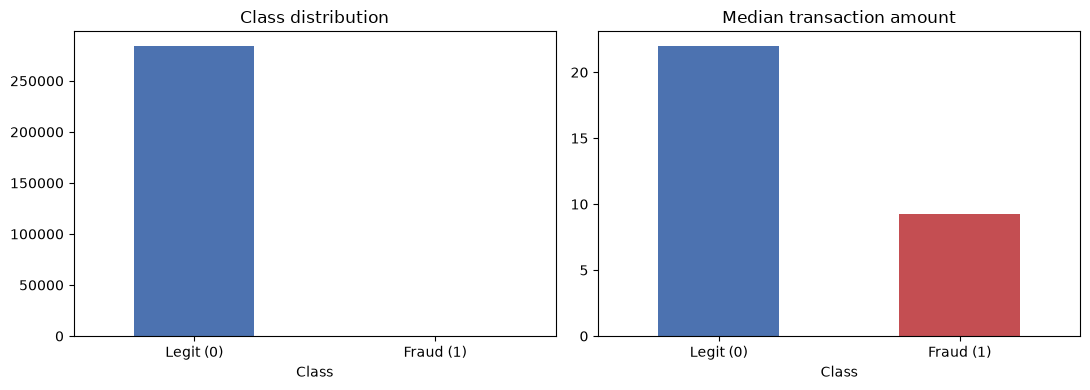

In [15]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Drop incomplete rows (e.g. a truncated last line from a partial download)
df = df.dropna().reset_index(drop=True)
df["Class"] = df["Class"].astype(int)
print("Shape after dropping incomplete rows:", df.shape)
if len(df) < 280000:
    print("WARNING: the full dataset has 284,807 rows. This file looks truncated; re-download it from Kaggle.")

counts = df["Class"].value_counts()
print("\nClass counts:\n", counts)
print(f"Fraud rate: {df['Class'].mean():.4%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts.plot(kind="bar", ax=ax[0], color=["#4c72b0", "#c44e52"])
ax[0].set_title("Class distribution"); ax[0].set_xticklabels(["Legit (0)", "Fraud (1)"], rotation=0)
df.groupby("Class")["Amount"].median().plot(kind="bar", ax=ax[1], color=["#4c72b0", "#c44e52"])
ax[1].set_title("Median transaction amount"); ax[1].set_xticklabels(["Legit (0)", "Fraud (1)"], rotation=0)
plt.tight_layout(); plt.show()

**Why accuracy is useless here:** a model that predicts "legit" for everything is ~99.83% accurate and catches zero fraud.
So we use **PR-AUC (average precision)**, **recall**, **precision** and **F1** on the fraud class.

## 2. Preprocessing and split

- `V1`-`V28` are already PCA-transformed, so only `Amount` and `Time` need handling.
- `Amount` is skewed, so use `RobustScaler` (**fit on train only** to avoid leakage).
- `Time` is seconds since the first transaction, so convert it to hour-of-day.
- Stratified 60 / 20 / 20 split: train (fit), validation (choose threshold), test (final report).

In [16]:
df = df.drop_duplicates().reset_index(drop=True)
df["Hour"] = (df["Time"] // 3600) % 24
df = df.drop(columns=["Time"])

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

scaler = RobustScaler().fit(X_train[["Amount"]])
for part in (X_train, X_val, X_test):
    part["Amount"] = scaler.transform(part[["Amount"]])

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: {len(part):>7,} rows | fraud = {int(part.sum()):>4} ({part.mean():.3%})")

train: 170,235 rows | fraud =  284 (0.167%)
val  :  56,745 rows | fraud =   94 (0.166%)
test :  56,746 rows | fraud =   95 (0.167%)


## 3. Evaluation helpers

In [17]:
def recall_at_precision(y_true, scores, min_precision=0.90):
    """Best recall achievable while keeping precision >= min_precision."""
    p, r, _ = precision_recall_curve(y_true, scores)
    ok = p >= min_precision
    return float(r[ok].max()) if ok.any() else 0.0

def evaluate(name, model, X, y, threshold=0.5):
    scores = model.predict_proba(X)[:, 1]
    preds = (scores >= threshold).astype(int)
    return {
        "Model": name,
        "PR-AUC": average_precision_score(y, scores),
        "ROC-AUC": roc_auc_score(y, scores),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds),
        "F1": f1_score(y, preds),
        "Recall@90%Prec": recall_at_precision(y, scores, 0.90),
    }

## 4. Models

Imbalance handled with class weights (`class_weight`, `scale_pos_weight`) first; SMOTE is compared afterwards.
All comparisons here are on the **validation** set. The test set is touched only once at the end.

In [18]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=neg / pos, eval_metric="aucpr",
        n_jobs=-1, random_state=RANDOM_STATE),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    results.append(evaluate(name, m, X_val, y_val))

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,PR-AUC,ROC-AUC,Precision,Recall,F1,Recall@90%Prec
Model,,,,,,
Logistic Regression,0.6979,0.9729,0.0558,0.8723,0.1049,0.0000
Random Forest,0.7902,0.9461,0.9444,0.7234,0.8193,0.7766
XGBoost,0.8062,0.9686,0.8902,0.7766,0.8295,0.7766


### SMOTE comparison (oversample the training set only)

In [19]:
sm = SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)   # fraud -> 10% of legit
X_sm, y_sm = sm.fit_resample(X_train, y_train)

rf_smote = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
).fit(X_sm, y_sm)

models["Random Forest + SMOTE"] = rf_smote
results.append(evaluate("Random Forest + SMOTE", rf_smote, X_val, y_val))
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,PR-AUC,ROC-AUC,Precision,Recall,F1,Recall@90%Prec
Model,,,,,,
Logistic Regression,0.6979,0.9729,0.0558,0.8723,0.1049,0.0000
Random Forest,0.7902,0.9461,0.9444,0.7234,0.8193,0.7766
XGBoost,0.8062,0.9686,0.8902,0.7766,0.8295,0.7766
Random Forest + SMOTE,0.8106,0.9651,0.9012,0.7766,0.8343,0.7766


### Precision-Recall curves (validation)

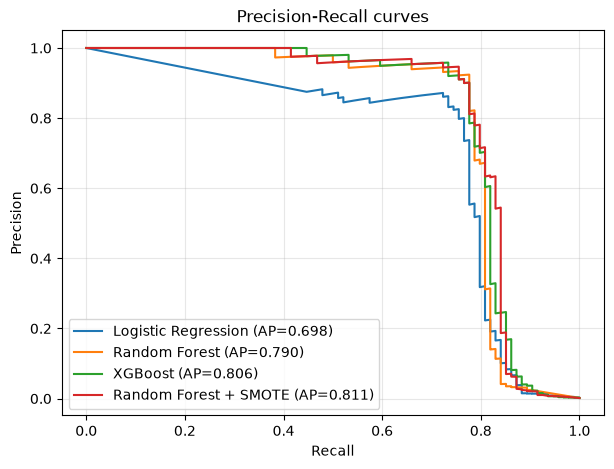

In [20]:
plt.figure(figsize=(7, 5))
for name, m in models.items():
    s = m.predict_proba(X_val)[:, 1]
    p, r, _ = precision_recall_curve(y_val, s)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_val, s):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curves")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 5. Cost-based threshold tuning

In fraud, a missed fraud (false negative) costs far more than a false alarm (false positive).
The costs below are **assumptions for illustration**; replace them with realistic values and state that in your write-up.
The threshold is picked on the **validation** set.

Best model by validation PR-AUC: Random Forest + SMOTE
Cost-optimal threshold: 0.15


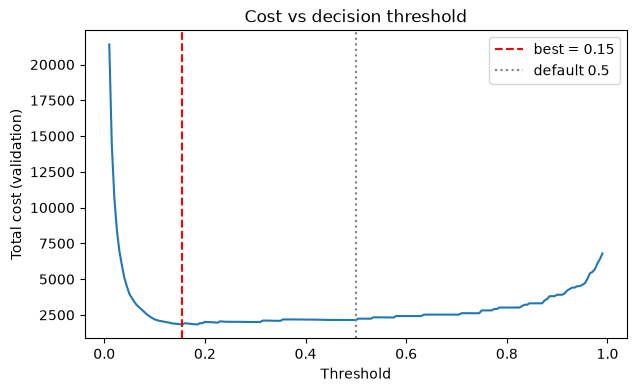

In [21]:
COST_FN = 100   # assumed average loss from one missed fraud
COST_FP = 5     # assumed cost of reviewing / declining one legit transaction

best_name = results_df["PR-AUC"].idxmax()
best_model = models[best_name]
print("Best model by validation PR-AUC:", best_name)

val_scores = best_model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.01, 0.99, 197)
costs = []
for t in thresholds:
    tn, fp, fn, tp = confusion_matrix(y_val, (val_scores >= t).astype(int)).ravel()
    costs.append(fn * COST_FN + fp * COST_FP)

best_t = float(thresholds[int(np.argmin(costs))])
print(f"Cost-optimal threshold: {best_t:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs)
plt.axvline(best_t, color="red", ls="--", label=f"best = {best_t:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="default 0.5")
plt.xlabel("Threshold"); plt.ylabel("Total cost (validation)")
plt.title("Cost vs decision threshold"); plt.legend(); plt.show()

## 6. Final evaluation on the untouched test set

,PR-AUC,ROC-AUC,Precision,Recall,F1,Recall@90%Prec
Model,,,,,,
Random Forest + SMOTE @0.50,0.8677,0.9865,0.9268,0.8000,0.8588,0.8211
Random Forest + SMOTE @0.15,0.8677,0.9865,0.5350,0.8842,0.6667,0.8211


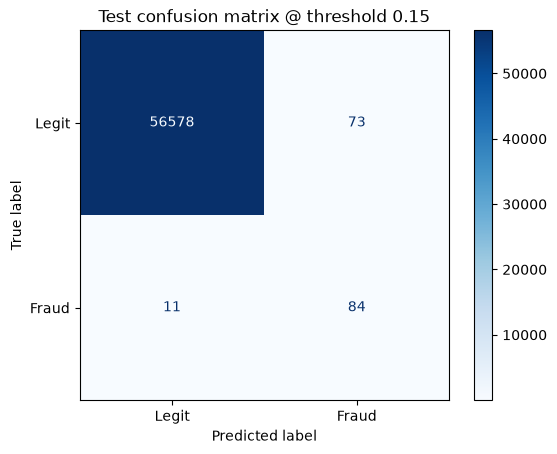

Caught 84 of 95 frauds; 73 false alarms out of 56651 legit transactions.


In [22]:
final_default = evaluate(f"{best_name} @0.50", best_model, X_test, y_test, 0.5)
final_tuned = evaluate(f"{best_name} @{best_t:.2f}", best_model, X_test, y_test, best_t)
display(pd.DataFrame([final_default, final_tuned]).set_index("Model").round(4))

test_scores = best_model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (test_scores >= best_t).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(cmap="Blues")
plt.title(f"Test confusion matrix @ threshold {best_t:.2f}"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp + fn} frauds; {fp} false alarms out of {tn + fp} legit transactions.")

## 7. Explainability with SHAP

SHAP shows which features push a transaction toward "fraud". The features `V1`-`V28` are anonymised (PCA),
so we can rank their influence but not name them in business terms. State this limitation in your write-up.

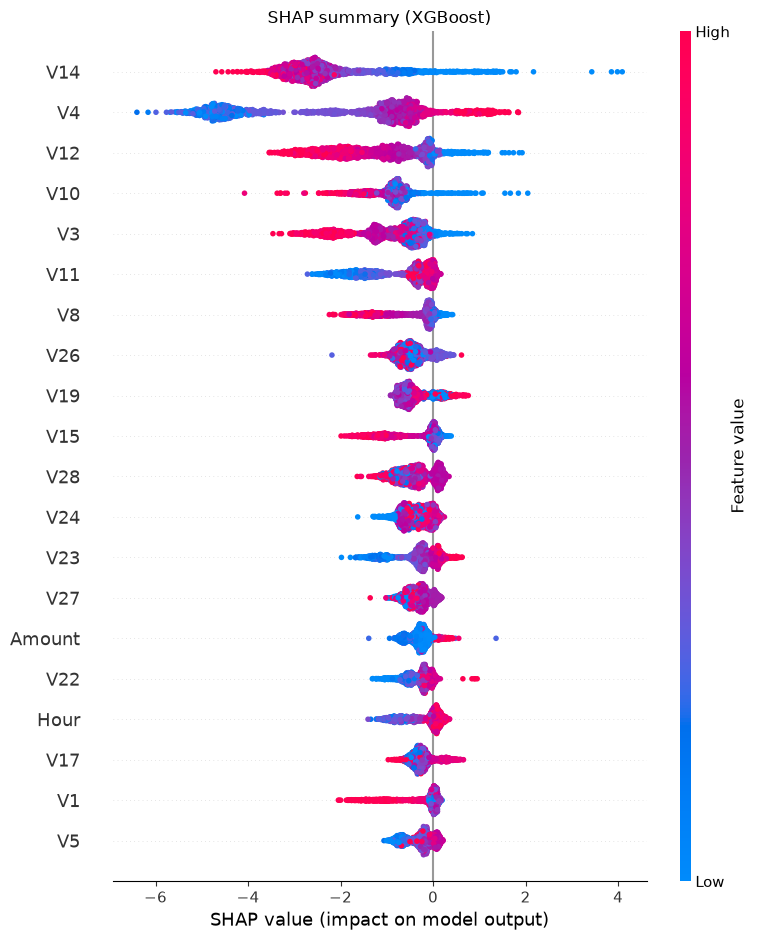

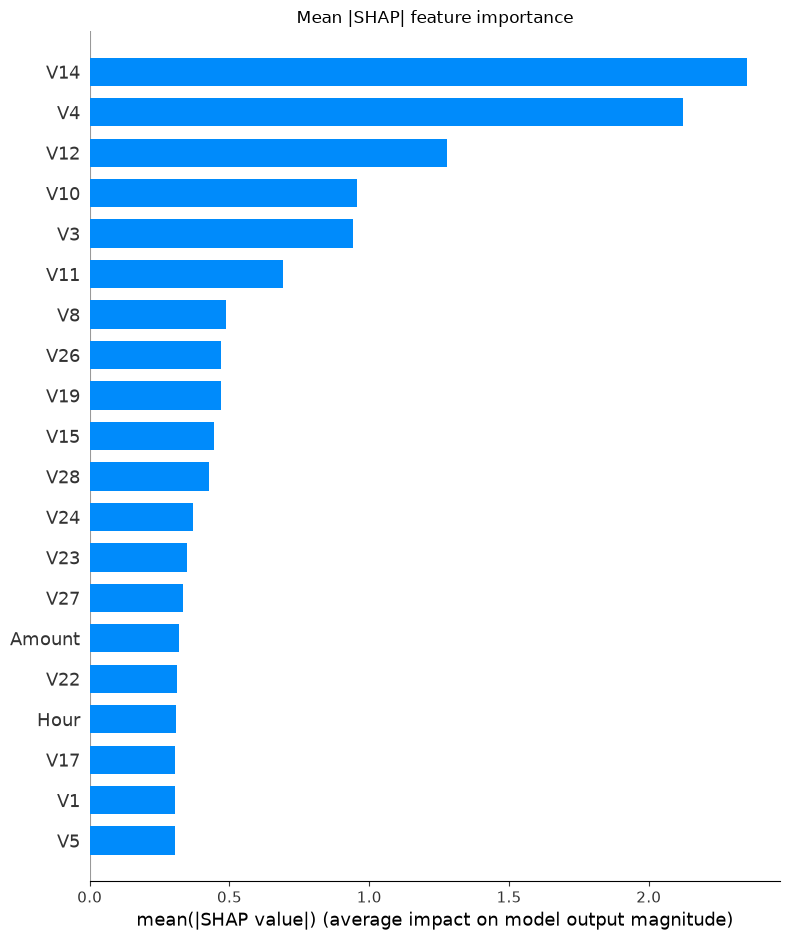

In [23]:
xgb_model = models["XGBoost"]
sample = X_test.sample(min(2000, len(X_test)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, show=False)
plt.title("SHAP summary (XGBoost)"); plt.tight_layout(); plt.show()

shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
plt.title("Mean |SHAP| feature importance"); plt.tight_layout(); plt.show()

## 8. Findings (fill in with YOUR numbers after running)

- Dataset: ___ transactions, ___% fraud; split 60/20/20 stratified.
- Best model: ___ with PR-AUC = ___ on validation; ___ on test.
- Class weights vs SMOTE: ___ (which did better and by how much).
- At the cost-optimal threshold (___), the model caught ___% of fraud with ___% precision on the test set.
- Top SHAP features: ___.
- Limitations: anonymised features, assumed costs, a single time-agnostic split (a time-based split would be a stricter test).
- Next steps: time-based validation, probability calibration, hyperparameter search (Optuna), monitoring for drift.